# Exercice 1 — Prédiction de la consommation électrique avec un Transformer

**Objectif :** utiliser les **24 dernières heures** de consommation pour prédire la consommation de **l'heure suivante**.

**Dataset :** *Individual Household Electric Power Consumption* (UCI Machine Learning Repository).
Variable utilisée : `Global_active_power`, agrégée **par heure** (puissance moyenne en kW).

> Le fichier `household_power_consumption.txt` (~130 Mo) n'est pas versionné sur GitHub.
> Le placer dans le dossier `data/` (voir `data/README.md`).

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

## 1. Préparation des données

In [2]:
# Chercher le fichier dans data/ (exécution depuis exercices/ ou depuis la racine du dépôt)
candidats = [Path("../data/household_power_consumption.txt"),
             Path("data/household_power_consumption.txt"),
             Path("household_power_consumption.txt")]
chemin = next((c for c in candidats if c.exists()), None)
assert chemin is not None, "Placer household_power_consumption.txt dans le dossier data/"

df = pd.read_csv(chemin, sep=";", na_values=["?"], low_memory=False)
df["datetime"] = pd.to_datetime(df["Date"] + " " + df["Time"], format="%d/%m/%Y %H:%M:%S")

puissance = pd.to_numeric(df["Global_active_power"], errors="coerce")
puissance.index = pd.DatetimeIndex(df["datetime"])

print("Mesures (1 par minute) :", len(puissance))
print("Période :", puissance.index.min(), "->", puissance.index.max())
print("Valeurs manquantes :", puissance.isna().sum())

Mesures (1 par minute) : 2075259
Période : 2006-12-16 17:24:00 -> 2010-11-26 21:02:00
Valeurs manquantes : 25979


In [3]:
# Puissance moyenne horaire : conserver les heures avec au moins 45 minutes renseignées.
horaire = puissance.resample("h").agg(["mean", "count"])
serie = horaire["mean"].where(horaire["count"] >= 45)

print("Heures :", len(serie), "| heures non exploitables :", serie.isna().sum())
serie.describe()

Heures : 34589 | heures non exploitables : 438


count    34151.000000
mean         1.091611
std          0.897600
min          0.124000
25%          0.341900
50%          0.802667
75%          1.579267
max          6.560533
Name: mean, dtype: float64

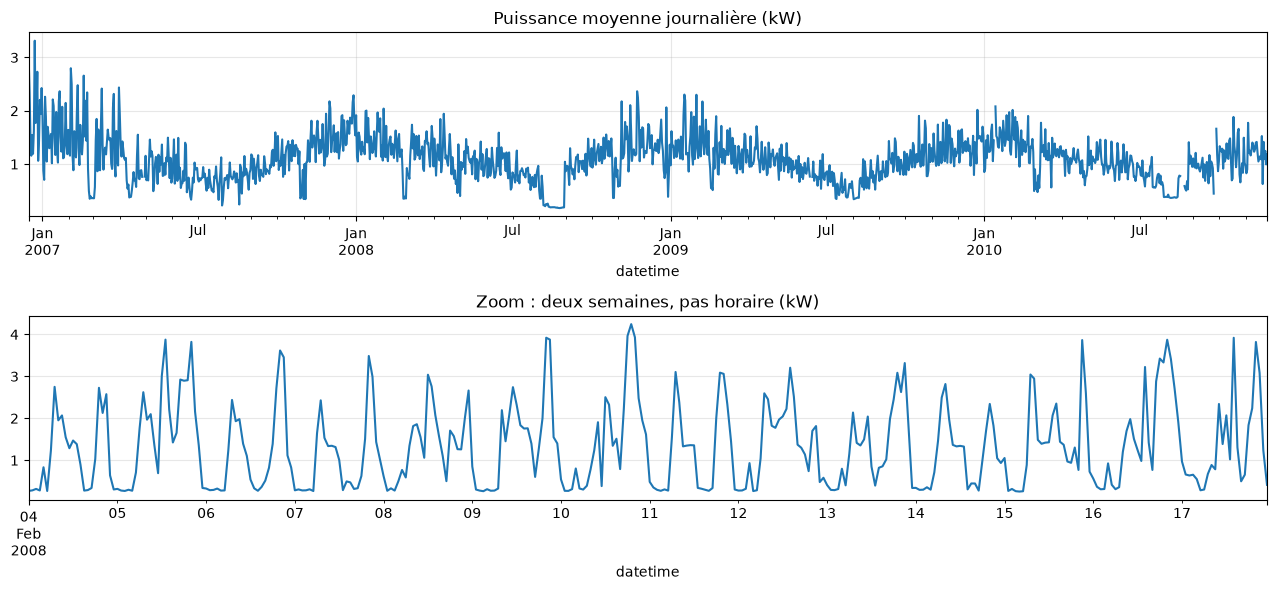

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6))
serie.resample("D").mean().plot(ax=axes[0], title="Puissance moyenne journalière (kW)")
serie["2008-02-04":"2008-02-17"].plot(ax=axes[1], title="Zoom : deux semaines, pas horaire (kW)")
for ax in axes:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
# Découpage chronologique : 70 % entraînement, 15 % validation, 15 % test.
n = len(serie)
fin_train = int(0.70 * n)
fin_val = int(0.85 * n)

# Normalisation calculée uniquement sur l'entraînement.
moyenne = serie.iloc[:fin_train].mean()
ecart_type = serie.iloc[:fin_train].std()
valeurs = ((serie - moyenne) / ecart_type).to_numpy()

print(f"moyenne = {moyenne:.4f} kW | écart-type = {ecart_type:.4f} kW")
print("Train jusqu'à", serie.index[fin_train - 1], "| Val jusqu'à", serie.index[fin_val - 1],
      "| Test jusqu'à", serie.index[-1])

moyenne = 1.0865 kW | écart-type = 0.9287 kW
Train jusqu'à 2009-09-20 12:00:00 | Val jusqu'à 2010-04-24 16:00:00 | Test jusqu'à 2010-11-26 21:00:00


In [6]:
def construire_fenetres(fenetre):
    """Fenêtres de `fenetre` heures -> heure suivante. Écarte les fenêtres avec des valeurs manquantes."""
    X, y, indices_cibles = [], [], []
    for i in range(fenetre, n):
        sequence = valeurs[i - fenetre:i]
        cible = valeurs[i]
        if np.isfinite(sequence).all() and np.isfinite(cible):
            X.append(sequence)
            y.append(cible)
            indices_cibles.append(i)
    X = torch.tensor(np.array(X), dtype=torch.float32).unsqueeze(-1)
    y = torch.tensor(np.array(y), dtype=torch.float32).unsqueeze(-1)
    indices_cibles = np.array(indices_cibles)
    masques = {
        "train": indices_cibles < fin_train,
        "val": (indices_cibles >= fin_train) & (indices_cibles < fin_val),
        "test": indices_cibles >= fin_val,
    }
    return X, y, indices_cibles, masques


def chargeurs(X, y, masques, batch_size=64):
    return {
        nom: DataLoader(TensorDataset(X[m], y[m]), batch_size=batch_size, shuffle=(nom == "train"))
        for nom, m in masques.items()
    }


fenetre = 24
X, y, dates_cibles, masques = construire_fenetres(fenetre)
loaders = chargeurs(X, y, masques)
train_loader, val_loader, test_loader = loaders["train"], loaders["val"], loaders["test"]

for nom, m in masques.items():
    print(f"{nom:<5} : {m.sum():6d} fenêtres")
print("Forme X :", tuple(X.shape), "| forme y :", tuple(y.shape))

train :  23805 fenêtres
val   :   5054 fenêtres
test  :   4932 fenêtres
Forme X : (33791, 24, 1) | forme y : (33791, 1)


## 2. Le modèle `EnergyTransformer`

| Couche | Configuration |
|---|---|
| Projection | `Linear(1, 32)` |
| Encodage positionnel | appris, un vecteur par heure (24 positions) |
| Encodeur | 2 × `TransformerEncoderLayer(d_model=32, nhead=4, dim_feedforward=128, dropout=0.1, batch_first=True)` |
| Sortie | `Linear(32, 1)` sur la représentation de la **dernière heure** |

```
Entrée                     : (batch, 24, 1)
Après projection           : (batch, 24, 32)
Après Transformer Encoder  : (batch, 24, 32)
Prédiction                 : (batch, 1)
```

In [7]:
class EnergyTransformer(nn.Module):
    def __init__(self, longueur=24, d_model=32, nhead=4, dim_feedforward=128, dropout=0.1, num_layers=2):
        super().__init__()
        self.projection = nn.Linear(1, d_model)
        self.positions = nn.Embedding(longueur, d_model)   # encodage positionnel des 24 heures
        couche = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=num_layers, enable_nested_tensor=False)
        self.sortie = nn.Linear(d_model, 1)

    def forward(self, x):
        indices = torch.arange(x.size(1), device=x.device)
        z = self.projection(x) + self.positions(indices).unsqueeze(0)   # (B, 24, 32)
        z = self.encodeur(z)                                            # (B, 24, 32)
        return self.sortie(z[:, -1, :])                                 # (B, 1)


modele = EnergyTransformer()
print("Paramètres :", sum(p.numel() for p in modele.parameters()))

with torch.no_grad():
    xb = X[:8]
    print("Entrée          :", tuple(xb.shape))
    z = modele.projection(xb)
    print("Après projection:", tuple(z.shape))
    print("Après encodeur  :", tuple(modele.encodeur(z).shape))
    print("Prédiction      :", tuple(modele(xb).shape))

Paramètres : 26273
Entrée          : (8, 24, 1)
Après projection: (8, 24, 32)


Après encodeur  : (8, 24, 32)
Prédiction      : (8, 1)


## 3. Entraînement et évaluation

Adam (lr = 0.001), perte MSE, **au maximum 20 époques**. On conserve le modèle ayant la **meilleure perte de validation**.

In [8]:
def evaluer_perte(modele, loader, critere):
    modele.eval()
    total, nb = 0.0, 0
    with torch.no_grad():
        for xb, yb in loader:
            total += critere(modele(xb), yb).item() * len(xb)
            nb += len(xb)
    return total / nb


def entrainer(modele, train_loader, val_loader, epochs=20, lr=1e-3):
    critere = nn.MSELoss()
    optimiseur = torch.optim.Adam(modele.parameters(), lr=lr)
    meilleure_val, meilleur_etat, hist = float("inf"), None, {"train": [], "val": []}

    for epoch in range(1, epochs + 1):
        debut = time.time()
        modele.train()
        total, nb = 0.0, 0
        for xb, yb in train_loader:
            perte = critere(modele(xb), yb)
            optimiseur.zero_grad()
            perte.backward()
            optimiseur.step()
            total += perte.item() * len(xb)
            nb += len(xb)
        perte_train = total / nb
        perte_val = evaluer_perte(modele, val_loader, critere)
        hist["train"].append(perte_train)
        hist["val"].append(perte_val)

        marque = ""
        if perte_val < meilleure_val:
            meilleure_val = perte_val
            meilleur_etat = {k: v.clone() for k, v in modele.state_dict().items()}
            marque = "  <- meilleur"
        print(f"Epoch {epoch:2d} | train {perte_train:.4f} | val {perte_val:.4f} | {time.time() - debut:4.1f}s{marque}")

    modele.load_state_dict(meilleur_etat)
    return hist, meilleure_val


torch.manual_seed(42)
modele = EnergyTransformer()
historique, meilleure_val = entrainer(modele, train_loader, val_loader, epochs=20)
print(f"\nMeilleure perte de validation (normalisée) : {meilleure_val:.4f}")

Epoch  1 | train 0.4698 | val 0.4081 |  7.0s  <- meilleur


Epoch  2 | train 0.4323 | val 0.3934 |  6.9s  <- meilleur


Epoch  3 | train 0.4258 | val 0.3975 |  7.1s


Epoch  4 | train 0.4185 | val 0.3864 |  7.8s  <- meilleur


Epoch  5 | train 0.4155 | val 0.3818 |  7.4s  <- meilleur


Epoch  6 | train 0.4125 | val 0.3907 |  7.3s


... (10 outputs left out)

Epoch 17 | train 0.3948 | val 0.3815 | 10.5s  <- meilleur


Epoch 18 | train 0.3952 | val 0.3798 | 10.4s  <- meilleur


Epoch 19 | train 0.3967 | val 0.3822 | 10.3s


Epoch 20 | train 0.3920 | val 0.3843 |  7.2s

Meilleure perte de validation (normalisée) : 0.3798


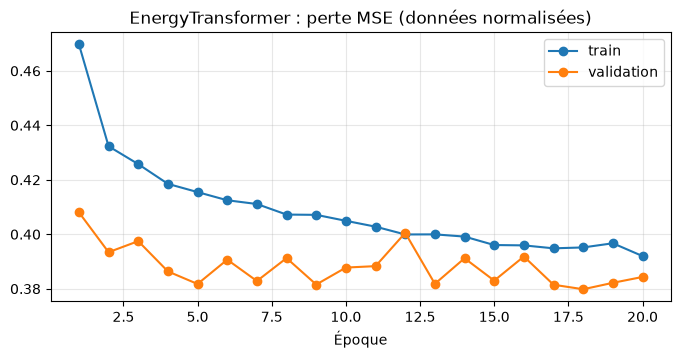

In [9]:
plt.figure(figsize=(8, 3.5))
plt.plot(range(1, 21), historique["train"], marker="o", label="train")
plt.plot(range(1, 21), historique["val"], marker="o", label="validation")
plt.title("EnergyTransformer : perte MSE (données normalisées)")
plt.xlabel("Époque")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Évaluation sur le test en kW + références

- **Persistance** : prédire la valeur de la dernière heure observée → `X[:, -1]`
- **Référence journalière** : prédire la valeur observée 24 heures auparavant → `X[:, 0]` (la fenêtre couvre `i-24 … i-1`)

Chaque prédiction utilise les 24 mesures **réellement observées** avant son heure cible (évaluation heure par heure).

In [10]:
def vers_kw(v):
    return v * ecart_type + moyenne


def mae_rmse(pred, vrai):
    erreur = pred - vrai
    return np.abs(erreur).mean(), np.sqrt((erreur ** 2).mean())


X_test, y_test = X[masques["test"]], y[masques["test"]]
modele.eval()
with torch.no_grad():
    pred_test = torch.cat([modele(xb) for xb, _ in DataLoader(TensorDataset(X_test, y_test), batch_size=512)])

vrai_kw = vers_kw(y_test.numpy().reshape(-1))
pred_kw = vers_kw(pred_test.numpy().reshape(-1))
persistance_kw = vers_kw(X_test[:, -1, 0].numpy())
journaliere_kw = vers_kw(X_test[:, 0, 0].numpy())

tableau = pd.DataFrame(
    [mae_rmse(pred_kw, vrai_kw), mae_rmse(persistance_kw, vrai_kw), mae_rmse(journaliere_kw, vrai_kw)],
    index=["EnergyTransformer", "Persistance (h-1)", "Référence journalière (h-24)"],
    columns=["MAE (kW)", "RMSE (kW)"],
).round(4)
tableau

,MAE (kW),RMSE (kW)
EnergyTransformer,0.3404,0.4917
Persistance (h-1),0.3892,0.5884
Référence journalière (h-24),0.5133,0.7639


In [11]:
gain = 1 - tableau.loc["EnergyTransformer"] / tableau.loc["Persistance (h-1)"]
print(f"Amélioration vs persistance : MAE {gain['MAE (kW)']:.1%} | RMSE {gain['RMSE (kW)']:.1%}")

Amélioration vs persistance : MAE 12.5% | RMSE 16.4%


### Prédictions sur sept jours consécutifs du test

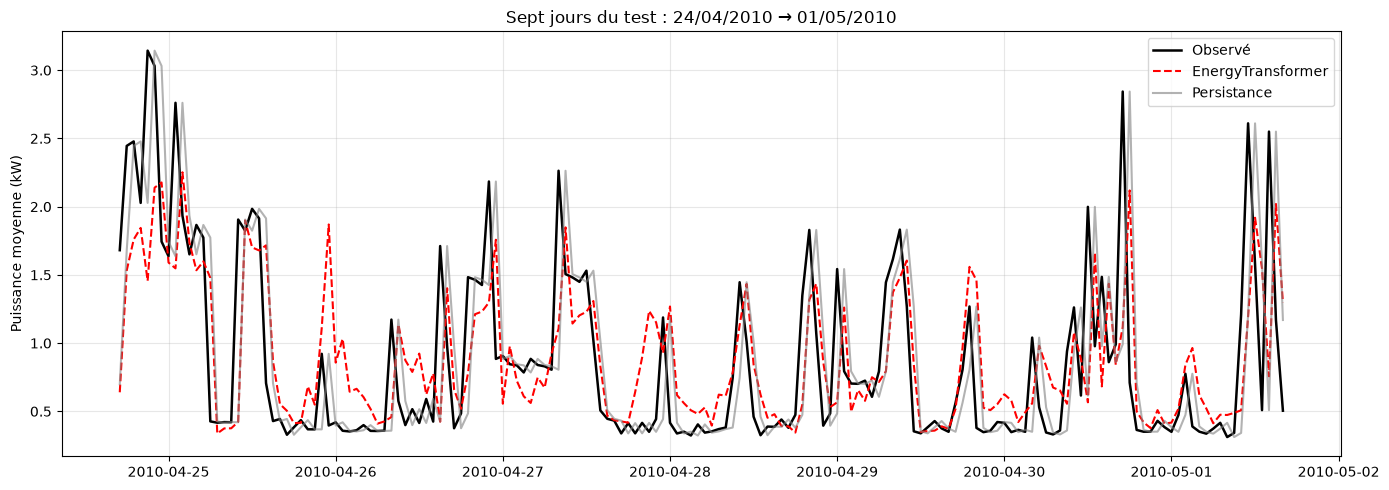

In [12]:
idx_test = dates_cibles[masques["test"]]
duree = 7 * 24
# Premier bloc de 168 heures consécutives sans trou dans le test
debut = next(j for j in range(len(idx_test) - duree) if idx_test[j + duree - 1] - idx_test[j] == duree - 1)
bloc = slice(debut, debut + duree)
dates = serie.index[idx_test[bloc]]

plt.figure(figsize=(14, 5))
plt.plot(dates, vrai_kw[bloc], label="Observé", color="black", linewidth=1.8)
plt.plot(dates, pred_kw[bloc], label="EnergyTransformer", color="red", linestyle="--")
plt.plot(dates, persistance_kw[bloc], label="Persistance", color="gray", alpha=0.6)
plt.title(f"Sept jours du test : {dates[0]:%d/%m/%Y} → {dates[-1]:%d/%m/%Y}")
plt.ylabel("Puissance moyenne (kW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Expérience : fenêtre de 168 heures (une semaine)

Même modèle, mêmes réglages (sauf **10 époques au maximum** pour limiter le temps de calcul sur CPU), mais 168 heures en entrée. On compare **sur les mêmes heures cibles**
(celles qui ont à la fois une fenêtre complète de 24 h et de 168 h).

> Cette expérience est plus longue (7 fois plus de positions, environ 15 fois plus lente par époque sur CPU). Mettre `LANCER_168 = False` pour la sauter.

In [13]:
LANCER_168 = True

if LANCER_168:
    X168, y168, dates168, masques168 = construire_fenetres(168)
    loaders168 = chargeurs(X168, y168, masques168)
    torch.manual_seed(42)
    modele168 = EnergyTransformer(longueur=168)
    hist168, _ = entrainer(modele168, loaders168["train"], loaders168["val"], epochs=10)

    modele168.eval()
    X168_test = X168[masques168["test"]]
    with torch.no_grad():
        pred168 = torch.cat([modele168(X168_test[k:k + 512]) for k in range(0, len(X168_test), 512)])
    pred168_kw = pd.Series(vers_kw(pred168.numpy().reshape(-1)), index=dates168[masques168["test"]])

    # Heures cibles communes aux deux expériences
    s24 = pd.Series(pred_kw, index=idx_test)
    vrai = pd.Series(vrai_kw, index=idx_test)
    communs = s24.index.intersection(pred168_kw.index)
    comparaison = pd.DataFrame(
        [mae_rmse(s24[communs].values, vrai[communs].values),
         mae_rmse(pred168_kw[communs].values, vrai[communs].values)],
        index=["Fenêtre 24 h", "Fenêtre 168 h"], columns=["MAE (kW)", "RMSE (kW)"],
    ).round(4)
    print(f"Heures cibles communes : {len(communs)}")
    display(comparaison)

Epoch  1 | train 0.4681 | val 0.3861 | 144.4s  <- meilleur


Epoch  2 | train 0.4139 | val 0.3915 | 148.0s


Epoch  3 | train 0.4066 | val 0.3895 | 127.3s


Epoch  4 | train 0.3985 | val 0.3625 | 121.8s  <- meilleur


Epoch  5 | train 0.3949 | val 0.3721 | 124.0s


Epoch  6 | train 0.3901 | val 0.3749 | 121.2s


... (2 outputs left out)

Epoch  9 | train 0.3836 | val 0.3547 | 150.3s  <- meilleur


Epoch 10 | train 0.3831 | val 0.3631 | 1117.2s


Heures cibles communes : 4644


,MAE (kW),RMSE (kW)
Fenêtre 24 h,0.3368,0.4875
Fenêtre 168 h,0.3298,0.4768


## 5. Questions de réflexion

| Modèle (test, 4 932 heures) | MAE (kW) | RMSE (kW) |
|---|---|---|
| **EnergyTransformer (24 h)** | **0.342** | **0.492** |
| Persistance (h-1) | 0.389 | 0.588 |
| Référence journalière (h-24) | 0.513 | 0.764 |

**Le Transformer améliore-t-il les deux références ?**
Oui. Par rapport à la persistance, la meilleure des deux références, la MAE baisse d'environ 12 % et la RMSE d'environ 16 %. Le gain est plus marqué sur la RMSE : le modèle commet moins de très grosses erreurs. La persistance, elle, est toujours « en retard d'une heure » sur les pics, ce qui se voit nettement sur le graphique des sept jours. La référence journalière (h-24) est la plus mauvaise : d'un jour à l'autre, les habitudes du foyer varient beaucoup (heures de pointe décalées, absences). L'écart reste modeste, car la consommation d'un seul foyer est très bruitée : un appareil allumé à une heure donnée est en grande partie imprévisible à partir de la seule courbe passée.

**Une fenêtre de 168 heures permet-elle de mieux capturer les habitudes hebdomadaires ?**
Légèrement, d'après notre expérience. Sur les mêmes heures cibles, la MAE passe de 0.339 à 0.334 kW et la RMSE de 0.488 à 0.478 kW, avec seulement 10 époques pour le modèle à 168 h contre 20 pour celui à 24 h. La fenêtre d'une semaine donne accès au même jour de la semaine précédente (week-end ou jour ouvré), mais :
- le gain est faible, car l'heure suivante dépend surtout des toutes dernières heures ;
- le coût est élevé : 7 fois plus de positions et environ 15 fois plus de temps par époque sur CPU (l'attention est quadratique en longueur) ;
- plus de fenêtres sont écartées à cause des valeurs manquantes.

**Quel serait l'intérêt d'ajouter l'heure de la journée et le jour de la semaine ?**
Le modèle ne reçoit que des valeurs de puissance. Il doit **deviner** à quel moment de la journée se trouve chaque fenêtre à partir de la forme de la courbe. Donner explicitement l'heure (en encodage cyclique sin/cos, pour que 23 h soit proche de 0 h) et le jour de la semaine (ou un indicateur week-end ou jour férié) lui fournit directement le facteur principal des habitudes du foyer : pics du matin et du soir, week-ends différents. On obtiendrait probablement un gain plus important et bien moins coûteux qu'une fenêtre de 168 h. En pratique, l'entrée passe de `(batch, 24, 1)` à `(batch, 24, k)` et la projection devient `Linear(k, 32)`.

**Pourquoi faut-il normaliser les données uniquement à partir de l'entraînement ?**
Pour éviter une **fuite d'information** (*data leakage*). La moyenne et l'écart-type calculés sur toute la série contiendraient des informations sur la période de validation et de test, c'est-à-dire sur le futur. L'évaluation serait alors trop optimiste et ne refléterait pas une utilisation réelle, où l'on ne connaît que le passé au moment de prédire. Les mêmes paramètres, issus de l'entraînement, sont ensuite appliqués tels quels à la validation et au test, puis utilisés pour revenir en kW (`valeur * ecart_type + moyenne`).

**La cible étant une puissance moyenne en kW, comment adapter la préparation pour prédire une énergie consommée en kWh ?**
L'énergie sur une heure est l'intégrale de la puissance : *E (kWh) = puissance moyenne (kW) × 1 h*. Avec des mesures à la minute, on calcule `Global_active_power / 60` (kWh par minute) puis on **somme** par heure (`resample("h").sum()`) au lieu de faire la moyenne. Pour les heures incomplètes, il ne faut pas sommer seulement les minutes disponibles, ce qui sous-estimerait l'énergie : soit on les écarte (seuil de 45 minutes, comme ici), soit on calcule `moyenne × 1 h`, ce qui revient à extrapoler les minutes manquantes. Avec des heures complètes, les deux sont équivalents : la valeur numérique en kWh sur une heure est égale à la puissance moyenne en kW. La différence apparaît pour d'autres pas de temps (par exemple 15 min : *E = P × 0.25*) ou pour des cumuls journaliers. Le reste du pipeline (normalisation sur l'entraînement, fenêtres, MAE/RMSE, désormais en kWh) ne change pas.
